# T4. Validation and the report in detail

The deployment decision rests on validation of the candidate that is deployed (the paper's algorithm
*Fixed-stage learning and independent deployment validation*).
Certificates from the value are useful too, but they are informative only in some regimes. This notebook goes
through both, with numpy only:

1. the direct binomial test and its **resolution floor**,
2. why the validation error is **allocated before** selecting among candidates,
3. the geometric clock versus a fixed horizon, and what the geometric risk says about when failures occur,
4. when the **value-based certificate** is informative,
5. a task with a physical horizon and a **lump sanction**, evaluated by your own vectorized simulator,
6. the anatomy of the report: what is established and what is not.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import barrierpg
from barrierpg import BudgetSpec, Requirement, Stage, BudgetWrapper, evaluate, evaluation_from_episodes, interpret
from barrierpg import validation as V
from barrierpg.examples.wear import WearModel, WearCore, wear_cost, make_wear_env, IncumbentRule

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. The direct test and its resolution floor

Draw $N$ fresh, independent episodes of the fixed candidate through action $T$ and count the failures $k$. The
one-sided exact binomial upper bound at error $\zeta$ is the $(1-\zeta)$ quantile of $\mathrm{Beta}(k+1,N-k)$.
With zero failures it is $1-\zeta^{1/N}$: **the resolution floor**. No sample certifies a tolerance below its floor,
and failure to certify does not prove a violation.

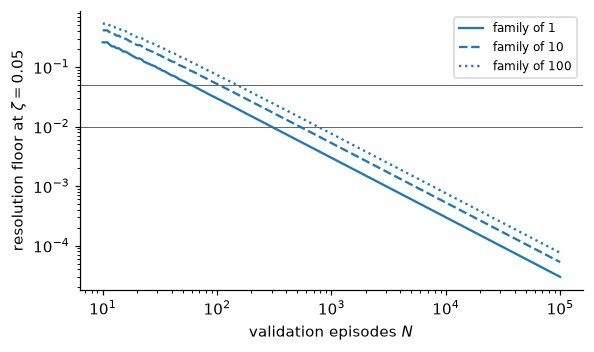

 alpha   expected rate   episodes needed (zeta = 0.05)
   0.1              0         29
   0.1           0.05        132
  0.05              0         59
  0.05          0.025        216
  0.01              0        299
  0.01          0.005       1059
 0.001              0       2995
 0.001         0.0005      10545


In [2]:
N = np.logspace(1, 5, 200)
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for fam, ls in ((1, "-"), (10, "--"), (100, ":")):
    ax.loglog(N, [V.resolution_floor(int(n), 0.05 / fam) for n in N], ls, color="C0", label=f"family of {fam}")
for a in (0.05, 0.01):
    ax.axhline(a, color="C3", lw=0.6)
ax.set_xlabel("validation episodes $N$"); ax.set_ylabel("resolution floor at $\\zeta=0.05$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(" alpha   expected rate   episodes needed (zeta = 0.05)")
for alpha in (0.1, 0.05, 0.01, 0.001):
    for rate in (0.0, alpha / 2):
        print(f"{alpha:6g}  {rate:13g}   {V.episodes_for_tolerance(alpha, 0.05, rate):8d}")

A candidate that fails at half the tolerance needs several times more episodes than a failure-free one.

## 2. Allocate the error before selecting

Suppose ten candidates all have the same true failure probability, 5.1%, just above the tolerance of 5%. We validate
each on 2000 episodes and deploy the one with the smallest upper bound. If every test uses the full error $\zeta=0.05$,
selecting the luckiest candidate inflates the chance of a false certificate. Splitting $\zeta$ over the family of
ten statements, before looking, keeps the simultaneous error at $\zeta$ (a union bound, which needs no independence).

In [3]:
rng = np.random.default_rng(0)
K, n, p_true, alpha, zeta, trials = 10, 2000, 0.051, 0.05, 0.05, 20_000
k_min = rng.binomial(n, p_true, size=(trials, K)).min(axis=1)
upper_naive = stats.beta.ppf(1 - zeta, k_min + 1, n - k_min)
upper_alloc = stats.beta.ppf(1 - zeta / K, k_min + 1, n - k_min)
print(f"probability of certifying a candidate that violates the tolerance: {np.mean(upper_naive <= alpha):.3f} with error zeta per test, "
      f"{np.mean(upper_alloc <= alpha):.3f} with zeta/K per test (the target is at most {zeta})")

probability of certifying a candidate that violates the tolerance: 0.243 with error zeta per test, 0.025 with zeta/K per test (the target is at most 0.05)


`Requirement(family=K)` and `validate_direct(..., family=K)` do this allocation.

## 3. The geometric clock versus a fixed horizon

Under geometric stopping (the wear wrapper's default), each period ends the episode with probability $1-\beta$.
A learner with discount one then optimizes the discounted objective exactly, and the failure indicator of an
episode has probability $q_\beta$. But the clock **censors** $p_T$: an episode stopped by the clock before $T$ says
nothing about failure at $T$. The toolbox then validates $q_\beta$ and uses $p_T\le\beta^{-T}q_\beta$, which is
conservative. To test $p_T$ directly, evaluate without the clock, over a fixed horizon.

In [4]:
model = WearModel(); spec = model.spec(ubar=1.0); stage = Stage(m=1.0)
rule = IncumbentRule(span=2.0, std=0.1, seed=0)
T = 19
geo = evaluate(lambda: make_wear_env(stage, model), rule, 10_000, spec=spec, stage=stage, seed=1, T=T)
fixed_spec = spec.with_(horizon=T + 1)
fixed = evaluate(lambda: BudgetWrapper(WearCore(model), wear_cost, fixed_spec, stage, geometric_stop=False), rule, 10_000,
                 spec=fixed_spec, stage=stage, seed=1, T=T)
vg = geo.validate(0.05 * spec.beta ** T, 0.05); vf = fixed.validate(0.05, 0.05)
print(f"geometric clock: q_beta = {geo.q_beta:.4f}; validated q_beta <= {vg.upper:.4f}; implied p_19 <= {vg.upper / spec.beta ** T:.4f}")
print(f"fixed horizon:   p_19   = {fixed.p_T:.4f}; validated p_19 <= {vf.upper:.4f}  -> {'certifies' if vf.passed else 'does not certify'} p_19 <= 0.05")
print(f"under the clock, {np.mean(geo.tau[geo.failed] > T):.0%} of the failures happen after action {T}")

geometric clock: q_beta = 0.0352; validated q_beta <= 0.0384; implied p_19 <= 0.1017
fixed horizon:   p_19   = 0.0007; validated p_19 <= 0.0013  -> certifies p_19 <= 0.05
under the clock, 99% of the failures happen after action 19


The two criteria measure different things. $q_\beta$ counts every failure before maintenance access, including
failures long after action $T$ in the episodes that last; this rule wears the allowance down slowly, so most of its
failures are late. The bound $p_T\le\beta^{-T}q_\beta$ is valid but loose here, and the direct test over the fixed
horizon certifies the requirement that the geometric route could not.

**When failures occur.** The geometric risk also bounds the failure time. With $\theta=\log(1/\beta)$,
$q_\beta=\mathbb E\,e^{-\theta\tau}$, and for every $\varepsilon\in(0,1]$ the earliest $\varepsilon$-fraction of failures
occurs on average no earlier than $\log(\varepsilon/q_\beta)/\theta$ periods (the paper's *The geometric risk as a risk
measure of the failure time*). With the validated upper bound on $q_\beta$ the statement is validated too. A bound on
$p_T$ at one horizon never says more than $T+1$, since it says nothing about failures after $T$.

In [5]:
from barrierpg.certificates import earliest_failures_time
for eps in (0.05, 0.1, 0.5):
    print(earliest_failures_time(vg.upper, spec.beta, eps).statement())

average time of the earliest failures, lower bound: 5.15467  [paper, 'The geometric risk as a risk measure of the failure time']
    the earliest 5% of failures occur on average no earlier than this many periods
    requires: q_beta is the geometric risk of the policy, or a valid upper bound on it
average time of the earliest failures, lower bound: 18.6681  [paper, 'The geometric risk as a risk measure of the failure time']
    the earliest 10% of failures occur on average no earlier than this many periods
    requires: q_beta is the geometric risk of the policy, or a valid upper bound on it
average time of the earliest failures, lower bound: 50.0452  [paper, 'The geometric risk as a risk measure of the failure time']
    the earliest 50% of failures occur on average no earlier than this many periods
    requires: q_beta is the geometric risk of the policy, or a valid upper bound on it


## 4. When is the value-based certificate informative?

The value certificate (the paper's *Value and objective certificates*) bounds the risk by the clipped value:
$p_T\le(\bar u-(1-\beta)V_m)/((m+\bar u)\beta^T)$. With validation
data, $V_m$ is replaced by a Hoeffding lower bound from returns truncated after $H$ actions. The factor $\beta^{-T}$
makes the bound grow with the horizon: it is informative only when $T$ is not large against $1/(1-\beta)$, and $H$
must exceed $T$ by enough that the omitted tail $\beta^{H-T}$ lies below the tolerance. Increasing the price helps
the numerator but cannot repair a failed resolution check.

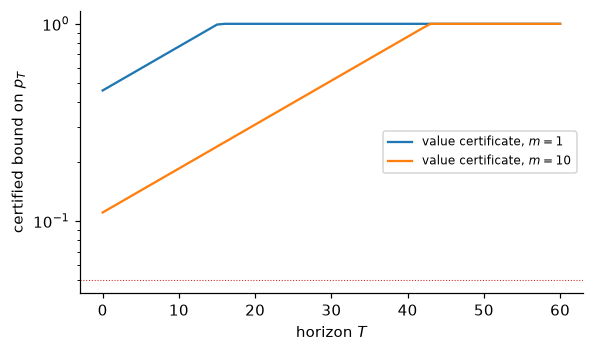

{1.0: 0.4594, 10.0: 0.1105} at T = 0
{'attainable': False, 'floor': 0.06039466640222681, 'alpha': 0.05, 'tail_term': 0.0012072363200535047, 'statistical_term': 0.0591874300821733}


In [6]:
H, Nv = 150, 3000
rows = {}
for m_ in (1.0, 10.0):
    st = Stage(m=m_)
    hs = spec.with_(horizon=H)
    ev = evaluate(lambda: BudgetWrapper(WearCore(model), wear_cost, hs, st, geometric_stop=False), IncumbentRule(3.0, 0.1, seed=2),
                  Nv, spec=hs, stage=st, seed=5, T=None)
    rows[m_] = [V.risk_from_validation_value(ev.clipped_returns.mean(), H, Nv, 0.05, m_, 1.0, spec.beta, t).value for t in range(0, 61)]
fig, ax = plt.subplots(figsize=(5.5, 3.3))
for m_, vals in rows.items():
    ax.plot(range(61), vals, label=f"value certificate, $m={m_:g}$")
ax.axhline(0.05, color="C3", lw=0.7, ls=":")
ax.set_xlabel("horizon $T$"); ax.set_ylabel("certified bound on $p_T$"); ax.set_yscale("log"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print({m_: round(v[0], 4) for m_, v in rows.items()}, "at T = 0")
print(V.value_resolution_check(beta=spec.beta, H=H, T=19, N=Nv, zeta=0.05, alpha=0.05))

The value certificate is valid at every $T$ and becomes vacuous within a few multiples of $1/(1-\beta)=20$
periods. Direct validation does not degrade with $T$ in this way; use it for the deployment decision.

## 5. A physical horizon and a lump sanction, with your own evaluator

Many tasks end after a fixed number of actions, and many sanctions are charged once. The paper's emissions
application is of this kind: 52 weeks, an annual allowance, and a sanction $F$ if the allowance turns negative.
The toolbox's form is a flat penalty $\nu=F$ at the failing week, `Stage(penalty="multiplier", multiplier=F)`, with
the pre-failure reward left unclipped; the value certificate is then $p_T\le(\bar uS_H-V^{(H)})/(F\beta^T)$.

Evaluation through the wrapper runs one episode at a time. For many candidates on common random numbers a
vectorized simulator is faster; `evaluation_from_episodes` builds the same `Evaluation` from its per-episode arrays.
Here is a stylized weekly emissions process (not the paper's estimated model) with a pacing rule as candidate.

In [7]:
def simulate_year(n, buffer, seed, F=50.0, b=31.7, c=6.0, H=52):
    """Weekly net emissions with a persistent shock; the rule abates at the constant rate that brings the forecast of
    year-end emissions to the allowance less a buffer. Returns per-year failure flag, failure week, stopped utility (minus
    the abatement cost) and the minimum remaining allowance fraction."""
    r = np.random.default_rng(seed)
    cum = np.zeros(n); shock = np.zeros(n); U = np.zeros(n); tau = np.full(n, -1); failed = np.zeros(n, bool); minres = np.ones(n)
    for t in range(H):
        weeks_left = H - t
        forecast = cum + weeks_left * (0.63 + 0.5 * shock)
        a = np.clip((forecast - (b - buffer)) / weeks_left, 0.0, 0.3)          # weekly abatement
        shock = 0.9 * shock + 0.05 * r.standard_normal(n)
        e = 0.63 + shock + 0.03 * r.standard_normal(n) - a
        alive = ~failed
        U[alive] -= 0.5 * c * a[alive] ** 2                                    # abatement cost before failure (beta ~ 1)
        cum = cum + e
        new_fail = alive & (cum > b)
        failed |= new_fail; tau[new_fail] = t
        minres = np.minimum(minres, np.maximum(b - cum, 0) / b)
    return failed, tau, U, minres


lump_spec = BudgetSpec(budgets=[31.7], beta=1 - 1e-6, ubar=0.0, u_minus=0.5 * 6.0 * 0.3 ** 2, horizon=52)
lump_stage = Stage(m=0.0, penalty="multiplier", multiplier=50.0, clip_utility=False)
lump_req = Requirement(T=51, alpha=0.05, zeta=0.05, family=3)
for buffer in (0.0, 1.0, 2.0):
    f, tau, U, mr = simulate_year(20_000, buffer, seed=11)
    ev = evaluation_from_episodes(f, tau, U, np.zeros_like(U), spec=lump_spec, stage=lump_stage, T=51, min_reserve=mr)
    v = ev.validate(lump_req.alpha, lump_req.zeta, lump_req.family)
    lump = V.lump_sanction_risk(ev.V_m, 52, 50.0, 0.0, lump_spec.beta, 51, N=ev.n, zeta=lump_req.error_per_statement, u_minus=lump_spec.u_minus)
    print(f"buffer {buffer}: miss probability {ev.p_T:.4f}, cost {-ev.U:.3f}; validated p_51 <= {v.upper:.4f}; lump-sanction value certificate {lump.value:.4f}")

buffer 0.0: miss probability 0.2785, cost 0.771; validated p_51 <= 0.2853; lump-sanction value certificate 0.3069
buffer 1.0: miss probability 0.0052, cost 1.088; validated p_51 <= 0.0064; lump-sanction value certificate 0.0399
buffer 2.0: miss probability 0.0009, cost 1.477; validated p_51 <= 0.0015; lump-sanction value certificate 0.0435


## 6. The anatomy of the report

`interpret` assembles three kinds of statements, as the paper separates them.

* **The reading of the objective.** With a known optimization error $\delta$, the fixed-price reading
  (*Fixed price of failure risk*): the candidate is optimal at the risk it attains, up to $\delta$. With `delta=None` the report
  makes no optimality claim.
* **Certificates and validation.** Each bound carries its source and hypotheses. The direct test at the specified
  horizon is the deployment decision.
* **What is not established.** Eventual risk, other horizons, other candidates, convergence of the training run,
  and model error.

In [8]:
f, tau, U, mr = simulate_year(20_000, 1.0, seed=12)
ev = evaluation_from_episodes(f, tau, U, np.zeros_like(U), spec=lump_spec, stage=lump_stage, T=51, min_reserve=mr)
rep = interpret(lump_spec, lump_req, lump_stage, ev, delta=None, candidate_name="the pacing rule with buffer 1")
print("certified:", rep.certified)
print("best bound on p_51:", rep.best_bound().statement() if rep.best_bound() else None, "\n")
print(rep.text())

certified: True
best bound on p_51: p_51 upper bound (validated): 0.00628417  [paper, 'Validate the deployed candidate at its specified horizon', exact binomial test]
    passes the tolerance 0.05; resolution floor 0.000205 (zero failures certify no less). Failure to certify does not prove violation; a passed test at one horizon does not certify a longer one
    requires: N fresh independent trajectories of the fixed candidate through action T; error 0.0167 allocated to this statement (family allocation) 

Candidate under the flat failure penalty nu = 50, charged once under the physical horizon H = 52; requirement p_51 <= 0.05 at error 0.05/3.

Measured on fresh episodes:
  n=20000: p_T(T=51)=0.0051 (102 failures counted for p_T), q_beta=0.0051, U=-1.072±0.0088, I_m=0, V_m=-1.327±0.029
  near-exhaustion (min reserve <=): 0.02b: 0.0318, 0.05b: 0.649, 0.1b: 0.866, 0.2b: 0.99

Verdict: CERTIFIED by direct validation at the specified horizon.

In what sense the candidate is a solution:
  -

## Two supplementary certificates

Both are proved in `docs/under-the-hood/supplementary-results.md` of the toolbox; neither is stated in the paper.

* **Near-exhaustion.** An interior barrier charges small reserves, so the clipped value also bounds the probability of
  coming within $\varepsilon$ of exhaustion: `certificates.near_exhaustion_bound` with `LogBarrier.lower_level`.
* **Eventual risk.** A small $q_\beta$ or a certificate at one $T$ does not bound $P(\tau<\infty)$ (the paper's example *Delay without eventual feasibility*).
  With bounded costs and cost discounts below one, a reserve above $\bar g_k/(1-\gamma_k)$ can never fail again, and
  $P(\tau<\infty)\le p_T+P(E_T)$ with both terms observable from $T+1$ actions: `certificates.eventual_risk_structural`.

In [9]:
from barrierpg import LogBarrier
from barrierpg.certificates import near_exhaustion_bound, unresolved_threshold, eventual_risk_structural
B = LogBarrier(0.1, [1.0])
for V in (4.0, 19.9):
    print(near_exhaustion_bound(V_m=V, m=1.0, ubar=1.0, beta=0.95, T=0, lower_barrier=B.lower_level([0.05])).statement())
print("(informative only for values close to the maximum ubar/(1-beta) = 20, because the barrier level at 5% of b is small)")
print("reserve that can never fail again with gbar = 0.1, gamma = 0.9:", unresolved_threshold(0.1, 0.9))
print(eventual_risk_structural(p_T=0.004, P_unresolved=0.002).statement())

near-exhaustion probability upper bound: 1  [toolbox, near-exhaustion certificate (docs/under-the-hood/supplementary-results.md)]
    requires: ubar is a valid upper bound on the one-step utility; V_m is a valid value (or a valid lower bound on it) of the policy under the stated reward convention; B_(eps) > 0 at the threshold eps
near-exhaustion probability upper bound: 0.328459  [toolbox, near-exhaustion certificate (docs/under-the-hood/supplementary-results.md)]
    requires: ubar is a valid upper bound on the one-step utility; V_m is a valid value (or a valid lower bound on it) of the policy under the stated reward convention; B_(eps) > 0 at the threshold eps
(informative only for values close to the maximum ubar/(1-beta) = 20, because the barrier level at 5% of b is small)
reserve that can never fail again with gbar = 0.1, gamma = 0.9: 1.0000000000000002
eventual risk upper bound: 0.006  [toolbox, structural certificate for eventual risk (docs/under-the-hood/supplementary-results.m

## Summary

* Validate the deployed candidate directly, at its horizon, with the error allocated over every candidate inspected.
* Zero failures certify the resolution floor, not zero; size $N$ before training.
* The value certificate needs no optimization guarantee but degrades like $\beta^{-T}$.
* Under geometric stopping, $p_T$ is censored: validate $q_\beta$, or evaluate over a fixed horizon.

The four problem notebooks (01 to 04) apply the whole workflow to RL-level problems with no exact benchmark.